In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [3]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5), (0.5))
    ])

transform = transforms.ToTensor()

mnist_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

data_loader = torch.utils.data.DataLoader(dataset=mnist_data,
                                          batch_size=64,
                                          shuffle=True)

mnist_data_valid = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

data_loader_valid = torch.utils.data.DataLoader(dataset=mnist_data_valid,
                                          batch_size=64,
                                          shuffle=True)             

In [4]:
dataiter = iter(data_loader)
images, labels = next(dataiter)
print(torch.min(images), torch.max(images))

tensor(0.) tensor(1.)


In [6]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()        
        # N, 1, 28, 28
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), # -> N, 16, 14, 14
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), # -> N, 32, 7, 7
            nn.ReLU(),
            nn.Conv2d(32, 64, 7) # -> N, 64, 1, 1
        )
        
        # N , 64, 1, 1
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 7), # -> N, 32, 7, 7
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), # N, 16, 14, 14 (N,16,13,13 without output_padding)
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), # N, 1, 28, 28  (N,1,27,27)
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [11]:
def add_noise(img, noise_factor=0.5):
    noisy = img + noise_factor * torch.randn_like(img)
    noisy = torch.clamp(noisy, 0., 1.)
    return noisy

In [12]:
def entrenar_ruido(model, num_epochs=10):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    train_losses, val_losses = [], []
    for epoch in range(num_epochs):
        model.train()
        total = 0
        for (img, _) in data_loader:
            recon = model(add_noise(img))
            loss = criterion(recon, img)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
        train_losses.append(total / len(data_loader))

        model.eval()
        total = 0
        with torch.no_grad():
            for (img, _) in data_loader_valid:
                recon = model(add_noise(img))
                total += criterion(recon, img).item()
        val_losses.append(total / len(data_loader_valid))

        print(f'Epoch:{epoch+1}, Loss:{train_losses[-1]:.4f}, Val Loss:{val_losses[-1]:.4f}')
    return train_losses, val_losses

model_ruido = Autoencoder()
train_losses, val_losses = entrenar_ruido(model_ruido)

Epoch:1, Loss:0.0389, Val Loss:0.0183
Epoch:2, Loss:0.0163, Val Loss:0.0146
Epoch:3, Loss:0.0141, Val Loss:0.0131
Epoch:4, Loss:0.0130, Val Loss:0.0123
Epoch:5, Loss:0.0124, Val Loss:0.0119
Epoch:6, Loss:0.0120, Val Loss:0.0117
Epoch:7, Loss:0.0118, Val Loss:0.0115
Epoch:8, Loss:0.0116, Val Loss:0.0113
Epoch:9, Loss:0.0115, Val Loss:0.0113
Epoch:10, Loss:0.0114, Val Loss:0.0112


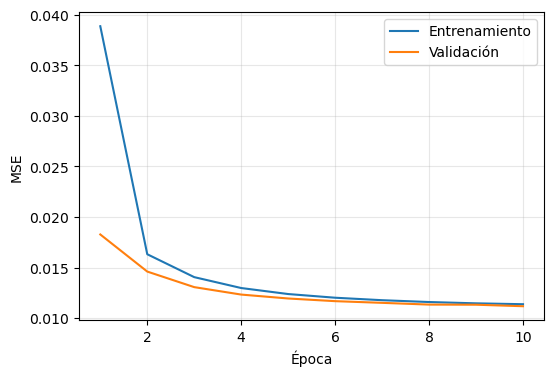

In [13]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), train_losses, label='Entrenamiento')
plt.plot(range(1, 11), val_losses, label='Validación')
plt.xlabel('Época')
plt.ylabel('MSE')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

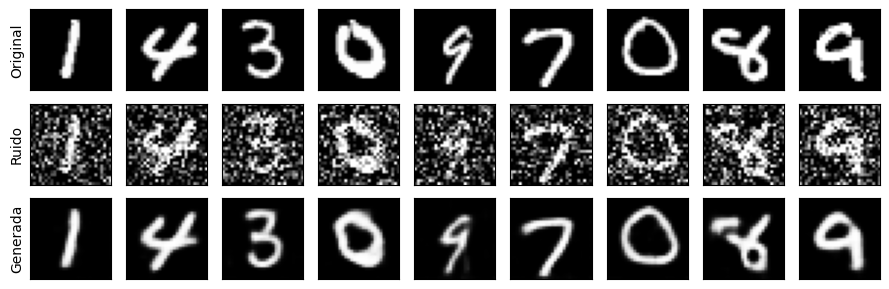

In [14]:
model_ruido.eval()

dataiter = iter(data_loader_valid)
images, labels = next(dataiter)
noisy_images = add_noise(images)

with torch.no_grad():
    recon = model_ruido(noisy_images)

plt.figure(figsize=(9, 3))
plt.gray()

for i in range(9):
    plt.subplot(3, 9, i+1)
    plt.imshow(images[i][0])
    plt.xticks([]); plt.yticks([])
    if i == 0: plt.ylabel('Original')

    plt.subplot(3, 9, 9+i+1)
    plt.imshow(noisy_images[i][0])
    plt.xticks([]); plt.yticks([])
    if i == 0: plt.ylabel('Ruido')

    plt.subplot(3, 9, 18+i+1)
    plt.imshow(recon[i][0])
    plt.xticks([]); plt.yticks([])
    if i == 0: plt.ylabel('Generada')

plt.tight_layout()
plt.show()

torch.Size([64, 1, 28, 28]) torch.Size([64, 1, 14, 14]) torch.Size([64, 1, 7, 7])


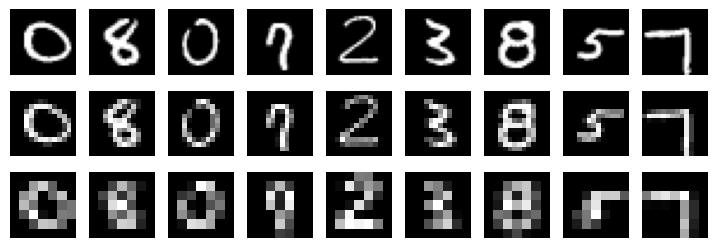

In [15]:
def reducir(imagenes, tam):
    return F.interpolate(imagenes, size=(tam, tam), mode='area')

imagenes, etiquetas = next(iter(data_loader_valid))
reducidas_14 = reducir(imagenes, 14)
reducidas_7 = reducir(imagenes, 7)
print(imagenes.shape, reducidas_14.shape, reducidas_7.shape)

plt.figure(figsize=(9, 3))
plt.gray()
for i in range(9):
    plt.subplot(3, 9, i + 1)
    plt.imshow(imagenes[i][0])
    plt.axis('off')

    plt.subplot(3, 9, 9 + i + 1)
    plt.imshow(reducidas_14[i][0])
    plt.axis('off')

    plt.subplot(3, 9, 18 + i + 1)
    plt.imshow(reducidas_7[i][0])
    plt.axis('off')
plt.show()

In [16]:
class AutoencoderSR(nn.Module):
    def __init__(self, tam_entrada):
        super().__init__()
        if tam_entrada == 14:
            self.encoder = nn.Sequential(
                nn.Conv2d(1, 32, 3, stride=2, padding=1),
                nn.ReLU(),
                nn.Conv2d(32, 64, 7)
            )
        elif tam_entrada == 7:
            self.encoder = nn.Sequential(
                nn.Conv2d(1, 32, 3, padding=1),
                nn.ReLU(),
                nn.Conv2d(32, 64, 7)
            )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 7),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

for tam in (14, 7):
    salida = AutoencoderSR(tam)(reducir(imagenes, tam))
    print(f'Entrada {tam}x{tam} -> salida {tuple(salida.shape)}')

Entrada 14x14 -> salida (64, 1, 28, 28)
Entrada 7x7 -> salida (64, 1, 28, 28)


In [17]:
def entrenar_sr(tam, num_epochs=10):
    model = AutoencoderSR(tam)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(),
                                 lr=1e-3,
                                 weight_decay=1e-5)
    perdidas_train, perdidas_valid = [], []

    for epoch in range(num_epochs):
        model.train()
        perdida_total = 0.0
        for (img, _) in data_loader:
            entrada = reducir(img, tam)
            recon = model(entrada)
            loss = criterion(recon, img)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            perdida_total += loss.item()

        model.eval()
        perdida_valid = 0.0
        with torch.no_grad():
            for (img, _) in data_loader_valid:
                perdida_valid += criterion(model(reducir(img, tam)), img).item()

        perdidas_train.append(perdida_total / len(data_loader))
        perdidas_valid.append(perdida_valid / len(data_loader_valid))
        print(f'{tam}x{tam} | Epoch:{epoch+1}, Loss:{perdidas_train[-1]:.4f}, Val Loss:{perdidas_valid[-1]:.4f}')

    return model, perdidas_train, perdidas_valid

modelos_sr, perdidas_sr = {}, {}
for tam in (14, 7):
    model, perdidas_train, perdidas_valid = entrenar_sr(tam)
    modelos_sr[tam] = model
    perdidas_sr[tam] = (perdidas_train, perdidas_valid)

14x14 | Epoch:1, Loss:0.0329, Val Loss:0.0097
14x14 | Epoch:2, Loss:0.0076, Val Loss:0.0060
14x14 | Epoch:3, Loss:0.0055, Val Loss:0.0048
14x14 | Epoch:4, Loss:0.0046, Val Loss:0.0042
14x14 | Epoch:5, Loss:0.0042, Val Loss:0.0039
14x14 | Epoch:6, Loss:0.0039, Val Loss:0.0037
14x14 | Epoch:7, Loss:0.0037, Val Loss:0.0035
14x14 | Epoch:8, Loss:0.0036, Val Loss:0.0035
14x14 | Epoch:9, Loss:0.0035, Val Loss:0.0034
14x14 | Epoch:10, Loss:0.0035, Val Loss:0.0034
7x7 | Epoch:1, Loss:0.0368, Val Loss:0.0168
7x7 | Epoch:2, Loss:0.0153, Val Loss:0.0135
7x7 | Epoch:3, Loss:0.0132, Val Loss:0.0123
7x7 | Epoch:4, Loss:0.0123, Val Loss:0.0116
7x7 | Epoch:5, Loss:0.0117, Val Loss:0.0111
7x7 | Epoch:6, Loss:0.0113, Val Loss:0.0109
7x7 | Epoch:7, Loss:0.0110, Val Loss:0.0105
7x7 | Epoch:8, Loss:0.0107, Val Loss:0.0102
7x7 | Epoch:9, Loss:0.0105, Val Loss:0.0102
7x7 | Epoch:10, Loss:0.0103, Val Loss:0.0099


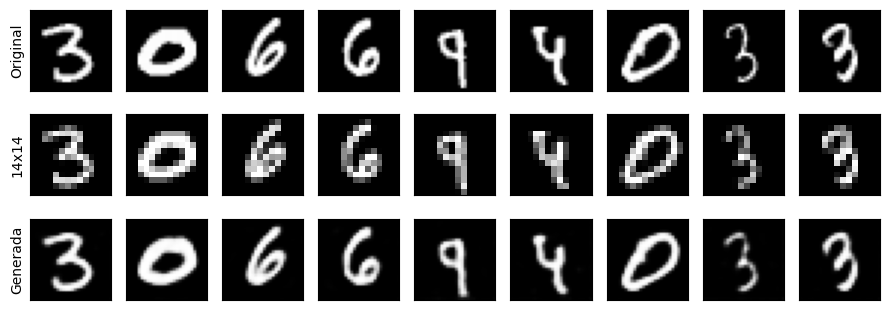

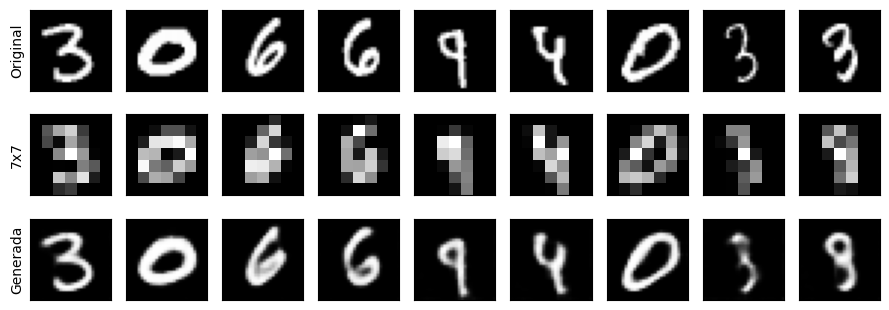

In [18]:
imagenes, etiquetas = next(iter(data_loader_valid))

for tam in (14, 7):
    modelos_sr[tam].eval()
    reducidas = reducir(imagenes, tam)
    with torch.no_grad():
        generadas = modelos_sr[tam](reducidas)

    plt.figure(figsize=(9, 3.4))
    plt.gray()
    for i in range(9):
        for fila, (datos, nombre) in enumerate([(imagenes, 'Original'), (reducidas, f'{tam}x{tam}'), (generadas, 'Generada')]):
            plt.subplot(3, 9, fila * 9 + i + 1)
            plt.imshow(datos[i][0])
            plt.xticks([])
            plt.yticks([])
            if i == 0:
                plt.ylabel(nombre)
    plt.tight_layout()
    plt.show()

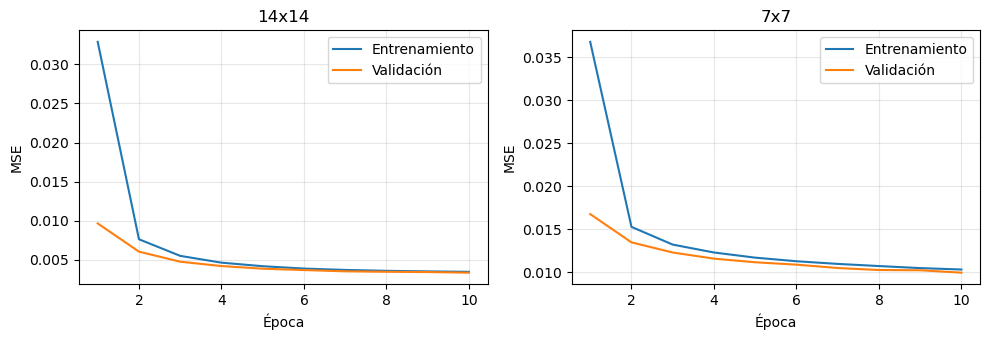

In [19]:
plt.figure(figsize=(10, 3.5))
for n, tam in enumerate((14, 7)):
    perdidas_train, perdidas_valid = perdidas_sr[tam]
    epocas = range(1, len(perdidas_train) + 1)
    plt.subplot(1, 2, n + 1)
    plt.plot(epocas, perdidas_train, label='Entrenamiento')
    plt.plot(epocas, perdidas_valid, label='Validación')
    plt.title(f'{tam}x{tam}')
    plt.xlabel('Época')
    plt.ylabel('MSE')
    plt.legend()
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

14x14 | MSE bilineal: 0.0146 | MSE autoencoder: 0.0034
7x7 | MSE bilineal: 0.0401 | MSE autoencoder: 0.0099


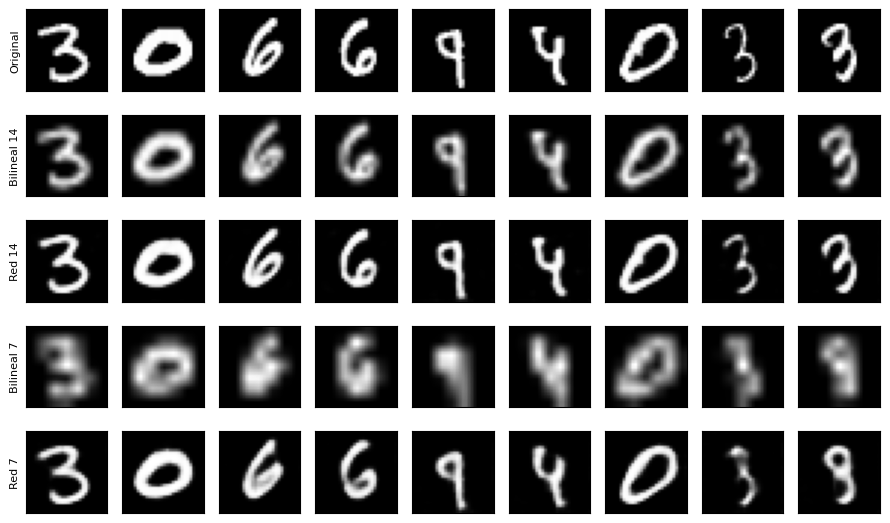

In [20]:
def ampliar_bilineal(img, tam):
    return F.interpolate(reducir(img, tam), size=(28, 28), mode='bilinear', align_corners=False)

def mse_valid(funcion):
    total = 0.0
    with torch.no_grad():
        for (img, _) in data_loader_valid:
            total += F.mse_loss(funcion(img), img).item()
    return total / len(data_loader_valid)

for tam in (14, 7):
    modelos_sr[tam].eval()
    mse_bilineal = mse_valid(lambda img: ampliar_bilineal(img, tam))
    mse_red = mse_valid(lambda img: modelos_sr[tam](reducir(img, tam)))
    print(f'{tam}x{tam} | MSE bilineal: {mse_bilineal:.4f} | MSE autoencoder: {mse_red:.4f}')

filas = [('Original', imagenes)]
with torch.no_grad():
    for tam in (14, 7):
        filas.append((f'Bilineal {tam}', ampliar_bilineal(imagenes, tam)))
        filas.append((f'Red {tam}', modelos_sr[tam](reducir(imagenes, tam))))

plt.figure(figsize=(9, 5.5))
plt.gray()
for f, (nombre, datos) in enumerate(filas):
    for i in range(9):
        plt.subplot(5, 9, f * 9 + i + 1)
        plt.imshow(datos[i][0])
        plt.xticks([])
        plt.yticks([])
        if i == 0:
            plt.ylabel(nombre, fontsize=8)
plt.tight_layout()
plt.show()